# LTAU 파라미터 그리드 라인플롯 (RMSE / R2 / PCC)

`results/{DATASET}/{TARGET}/v1/LTAU_BIN{BINS}_K{K}/metrics.csv`를 모아,
x축 = `LTAU_BINS` (5, 50, 500, 5000, 50000, log scale), 각 라인 = `LTAU_K` (3, 5, 7)
인 라인플롯을 RMSE / R2 / PCC 각각 **별도 figure**로 그린다 (subplot 사용 안 함).

## 저장 구조 (제안)

기존 `results/plots/ltau_param_comparison/{DATASET}/{TARGET}_{metric}.png` 네이밍과
동일한 컨벤션을 따라:

```
results/plots/ltau_param_lineplot/{DATASET}/{TARGET}_{metric}.png
```

예: `results/plots/ltau_param_lineplot/DIS/PI_rmse.png`

데이터셋(DIS/INH)당 폴더 1개, 그 안에 target×metric 조합별 PNG 1장. 총 2 × 4 × 3 = 24장.

In [ ]:
from pathlib import Path
from typing import Optional

import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# Config
# --------------------------------------------------
NOTEBOOK_DIR = Path.cwd()
REPO_ROOT = NOTEBOOK_DIR.parent.parent  # notebook/ltau_param -> cmfe
RESULTS_ROOT = REPO_ROOT / "results"
SAVE_ROOT = RESULTS_ROOT / "plots" / "ltau_param_lineplot"

VERSION = "v1"
DATASETS = ["DIS", "INH"]
TARGETS = ["PI", "Ssel", "WS2", "RS2"]

LTAU_BINS_LIST = [5, 50, 500, 5000, 50000]
LTAU_K_LIST = [3, 5, 7]

METRICS = ["rmse", "r2", "pcc"]
METRIC_LABELS = {"rmse": "RMSE", "r2": "R2", "pcc": "PCC"}

MODEL_NAME = "mlp"

# Fixed categorical color per K (dataviz skill: colorblind-safe, validated
# first-3-slots-all-pairs categorical order). Color follows the entity (K),
# never the rank of which K's happen to be present in a given plot.
K_COLOR = {
    3: "#ff218c",
    5: "#ffd800",
    7: "#21b1ff",
}

## 1. 데이터 로딩

각 `(dataset, target, k, bins)` 조합의 `metrics.csv`를 읽어 `model_name == "mlp"` 행에서
`rmse`/`r2`/`pcc`를 뽑는다. 아직 돌지 않은 그리드 포인트(예: `LTAU_BIN50_K*`,
`LTAU_BIN50000_K*`)는 파일이 없을 수 있으므로 건너뛰고 개수만 리포트한다.

In [2]:
def _grid_point_dir(target: str, k: int, bins: int) -> str:
    """Folder name for one (k, bins) grid point.

    BINS=5000, K=5 matches the base CUE run's own LTAU config exactly
    (see CUE/config.json: ltau_bins=5000, ltau_k=5), so that grid point is
    read directly from the CUE source run instead of a LTAU_BIN.../ folder.
    """
    if bins == 5000 and k == 5:
        return "CUE"
    return f"LTAU_BIN{bins}_K{k}"


def load_metric_row(dataset: str, target: str, k: int, bins: int) -> Optional[dict]:
    """Read metrics.csv for one (dataset, target, k, bins) grid point."""
    path = RESULTS_ROOT / dataset / target / VERSION / _grid_point_dir(target, k, bins) / "metrics.csv"
    if not path.exists():
        return None

    df = pd.read_csv(path)
    row = df[df["model_name"] == MODEL_NAME]
    if row.empty:
        return None

    row = row.iloc[0]
    return {
        "dataset": dataset,
        "target": target,
        "k": k,
        "bins": bins,
        "rmse": float(row["rmse"]),
        "r2": float(row["r2"]),
        "pcc": float(row["pcc"]),
    }


records = []
missing = []

for dataset in DATASETS:
    for target in TARGETS:
        for k in LTAU_K_LIST:
            for bins in LTAU_BINS_LIST:
                rec = load_metric_row(dataset, target, k, bins)
                if rec is None:
                    missing.append((dataset, target, k, bins))
                else:
                    records.append(rec)

df_all = pd.DataFrame(records)
print(f"[INFO] loaded {len(df_all)} grid points, missing {len(missing)}")
if missing:
    print("[WARN] missing (dataset, target, k, bins):")
    for m in missing:
        print("  ", m)

df_all.sort_values(["dataset", "target", "k", "bins"]).reset_index(drop=True)

[INFO] loaded 120 grid points, missing 0


,dataset,target,k,bins,rmse,r2,pcc
0,Kd,PI,3,5,0.245606,0.095572,0.344947
1,Kd,PI,3,50,0.243521,0.110714,0.354333
2,Kd,PI,3,500,0.243266,0.112567,0.355607
3,Kd,PI,3,5000,0.241410,0.126127,0.366206
4,Kd,PI,3,50000,0.243300,0.112149,0.353411
...,...,...,...,...,...,...,...
115,Ki,WS(alpha=2),7,5,0.212282,0.245486,0.503827
116,Ki,WS(alpha=2),7,50,0.211894,0.248282,0.504646
117,Ki,WS(alpha=2),7,500,0.212195,0.246089,0.505010
118,Ki,WS(alpha=2),7,5000,0.211729,0.249497,0.509041


## 2. 라인플롯 함수

`(dataset, target, metric)` 하나당 독립된 figure 하나. x축은 `LTAU_BINS`(log scale),
라인은 `LTAU_K`별로 3개(고정 색상).

In [3]:
def plot_lineplot(df_all: pd.DataFrame, dataset: str, target: str, metric: str) -> None:
    sub = df_all[(df_all["dataset"] == dataset) & (df_all["target"] == target)]
    if sub.empty:
        print(f"[skip] no data for dataset={dataset}, target={target}")
        return

    fig, ax = plt.subplots(figsize=(6, 4.5))

    for k in LTAU_K_LIST:
        line = sub[sub["k"] == k].sort_values("bins")
        if line.empty:
            continue
        ax.plot(
            line["bins"],
            line[metric],
            marker="o",
            markersize=8,
            linewidth=2,
            color=K_COLOR[k],
            label=f"K={k}",
        )

    ax.set_xscale("log")
    ax.set_xticks(LTAU_BINS_LIST)
    ax.set_xticklabels([str(b) for b in LTAU_BINS_LIST])
    ax.minorticks_off()

    ax.set_xlabel("LTAU_BINS")
    ax.set_ylabel(METRIC_LABELS[metric])
    ax.set_title(f"{dataset} / {target} \u2014 {METRIC_LABELS[metric]}")

    ax.grid(True, axis="both", alpha=0.3, linewidth=0.6)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(frameon=False, title="LTAU_K")

    fig.tight_layout()

    out_dir = SAVE_ROOT / dataset
    out_dir.mkdir(parents=True, exist_ok=True)
    out_path = out_dir / f"{target}_{metric}.png"
    fig.savefig(out_path, dpi=150)

    plt.show()
    plt.close(fig)

    print(f"[saved] {out_path}")

## 3. 전체 생성

`dataset x target x metric` 전 조합에 대해 개별 라인플롯 생성 및 저장.

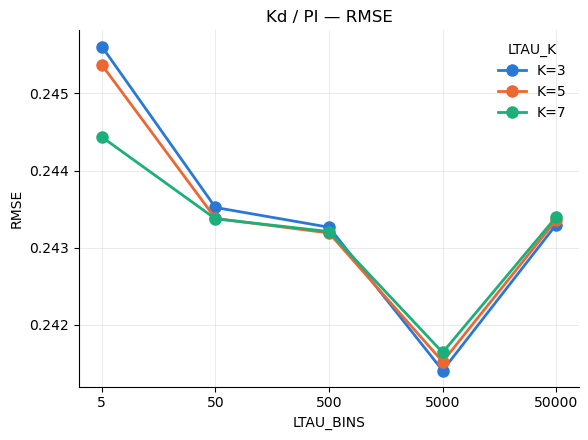

[saved] /data/rlawlsgurjh/work/gitlab/CUE/cmfe/results/plots/ltau_param_lineplot/Kd/PI_rmse.png


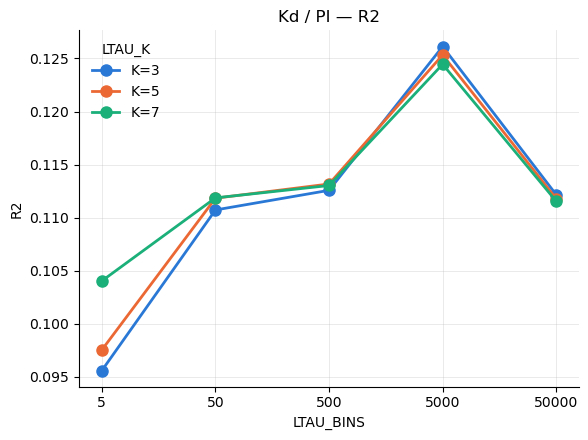

[saved] /data/rlawlsgurjh/work/gitlab/CUE/cmfe/results/plots/ltau_param_lineplot/Kd/PI_r2.png


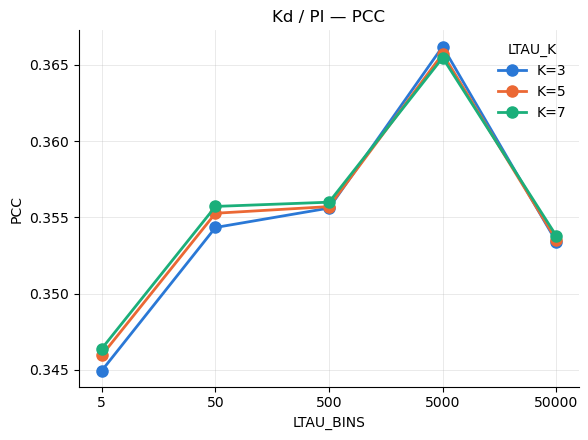

[saved] /data/rlawlsgurjh/work/gitlab/CUE/cmfe/results/plots/ltau_param_lineplot/Kd/PI_pcc.png


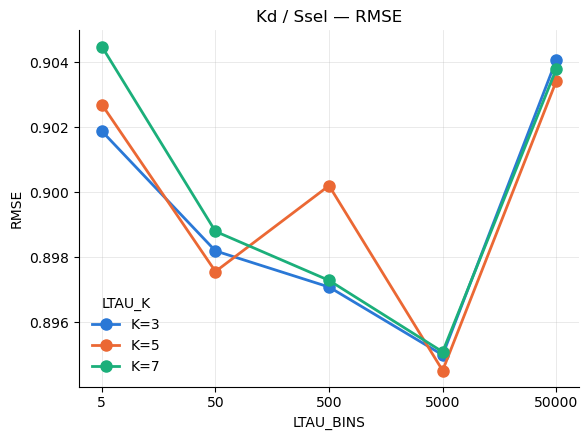

[saved] /data/rlawlsgurjh/work/gitlab/CUE/cmfe/results/plots/ltau_param_lineplot/Kd/Ssel_rmse.png


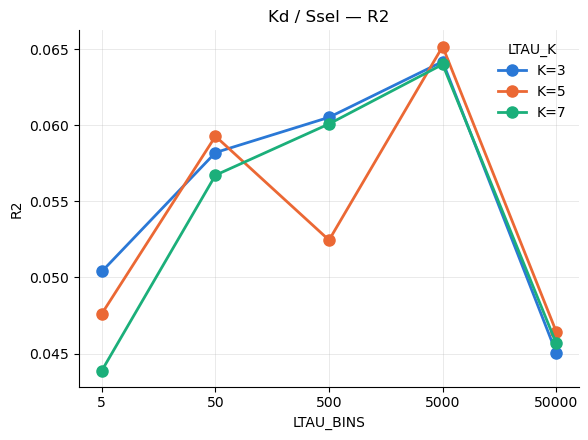

[saved] /data/rlawlsgurjh/work/gitlab/CUE/cmfe/results/plots/ltau_param_lineplot/Kd/Ssel_r2.png


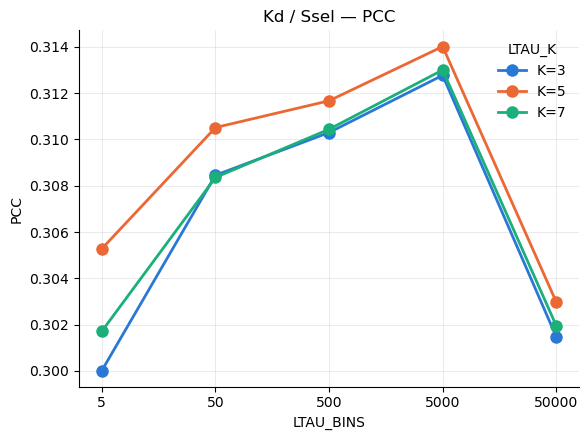

[saved] /data/rlawlsgurjh/work/gitlab/CUE/cmfe/results/plots/ltau_param_lineplot/Kd/Ssel_pcc.png


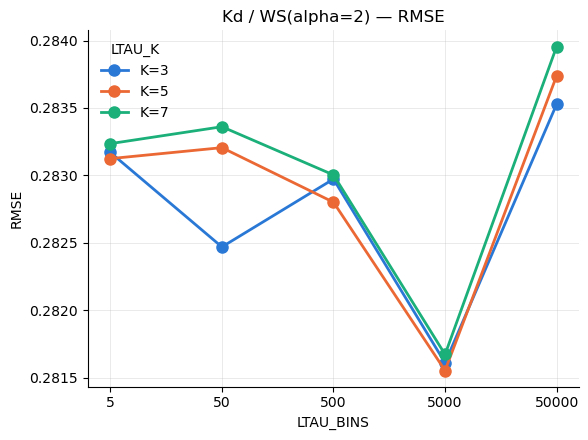

[saved] /data/rlawlsgurjh/work/gitlab/CUE/cmfe/results/plots/ltau_param_lineplot/Kd/WS(alpha=2)_rmse.png


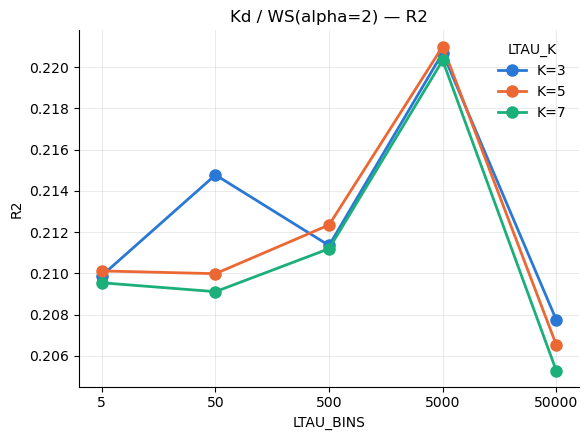

[saved] /data/rlawlsgurjh/work/gitlab/CUE/cmfe/results/plots/ltau_param_lineplot/Kd/WS(alpha=2)_r2.png


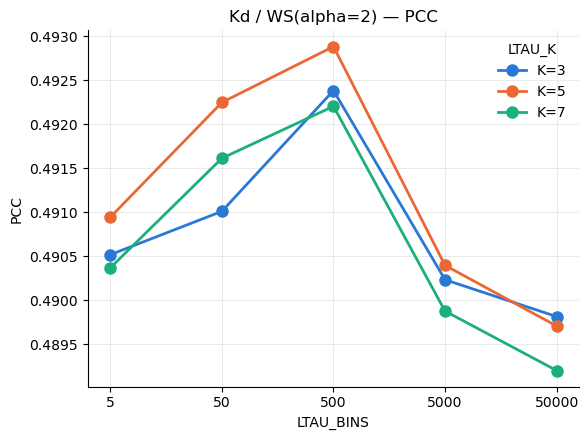

[saved] /data/rlawlsgurjh/work/gitlab/CUE/cmfe/results/plots/ltau_param_lineplot/Kd/WS(alpha=2)_pcc.png


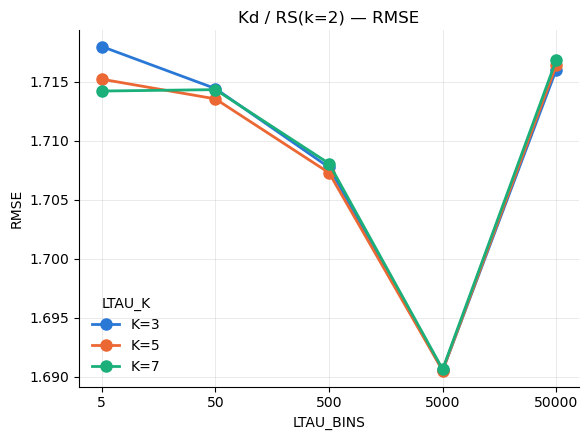

[saved] /data/rlawlsgurjh/work/gitlab/CUE/cmfe/results/plots/ltau_param_lineplot/Kd/RS(k=2)_rmse.png


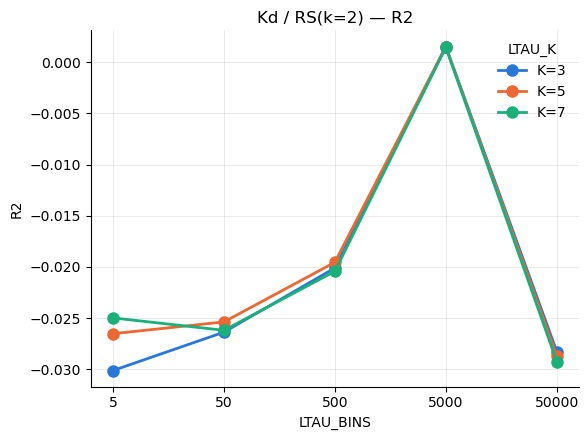

[saved] /data/rlawlsgurjh/work/gitlab/CUE/cmfe/results/plots/ltau_param_lineplot/Kd/RS(k=2)_r2.png


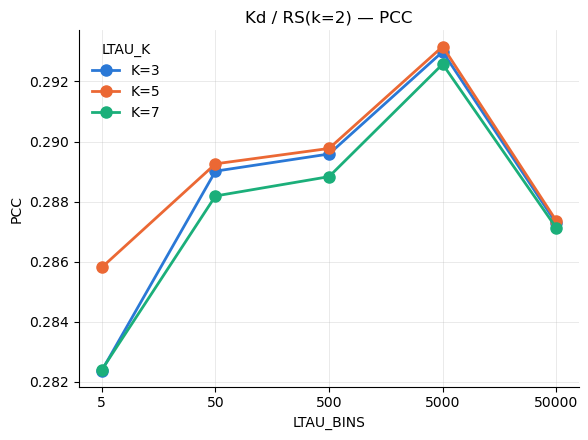

[saved] /data/rlawlsgurjh/work/gitlab/CUE/cmfe/results/plots/ltau_param_lineplot/Kd/RS(k=2)_pcc.png


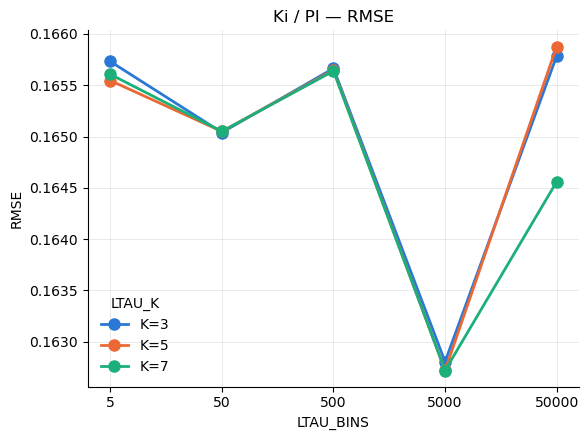

[saved] /data/rlawlsgurjh/work/gitlab/CUE/cmfe/results/plots/ltau_param_lineplot/Ki/PI_rmse.png


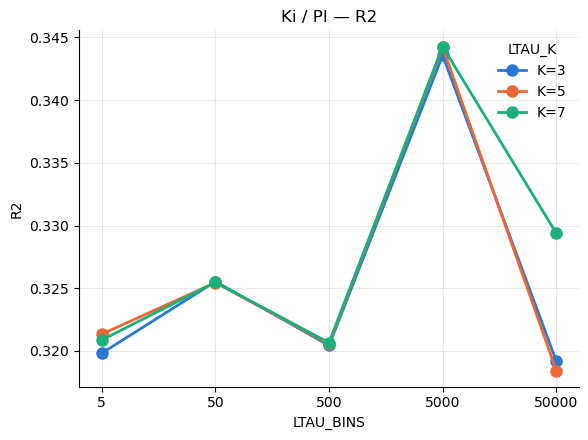

[saved] /data/rlawlsgurjh/work/gitlab/CUE/cmfe/results/plots/ltau_param_lineplot/Ki/PI_r2.png


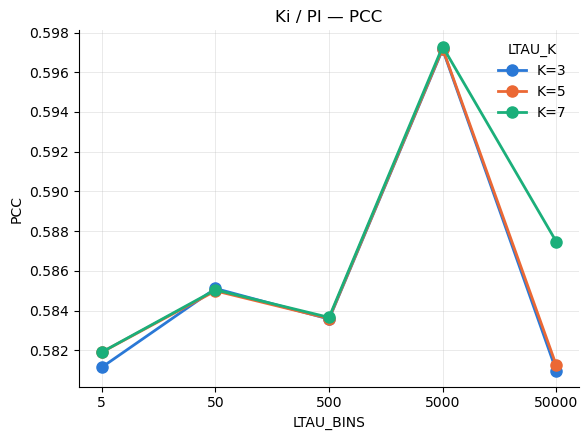

[saved] /data/rlawlsgurjh/work/gitlab/CUE/cmfe/results/plots/ltau_param_lineplot/Ki/PI_pcc.png


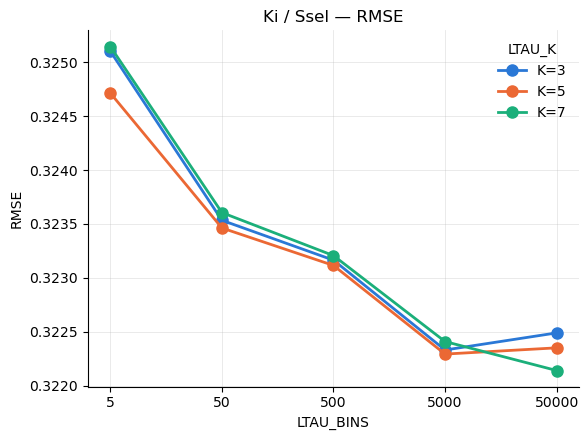

[saved] /data/rlawlsgurjh/work/gitlab/CUE/cmfe/results/plots/ltau_param_lineplot/Ki/Ssel_rmse.png


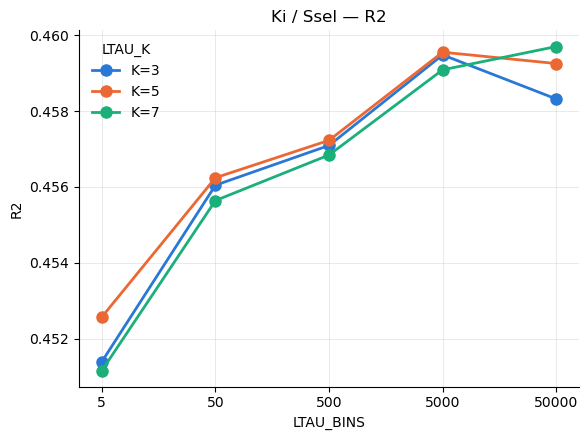

[saved] /data/rlawlsgurjh/work/gitlab/CUE/cmfe/results/plots/ltau_param_lineplot/Ki/Ssel_r2.png


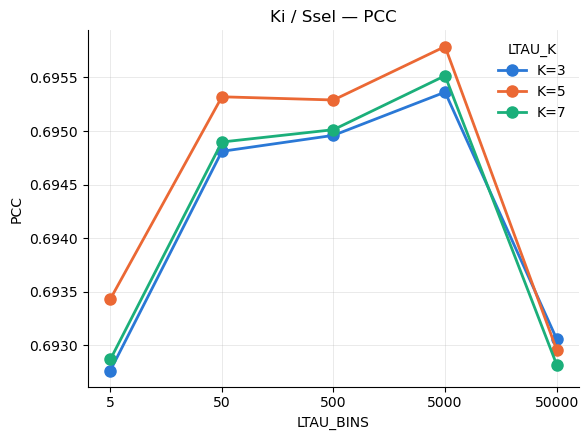

[saved] /data/rlawlsgurjh/work/gitlab/CUE/cmfe/results/plots/ltau_param_lineplot/Ki/Ssel_pcc.png


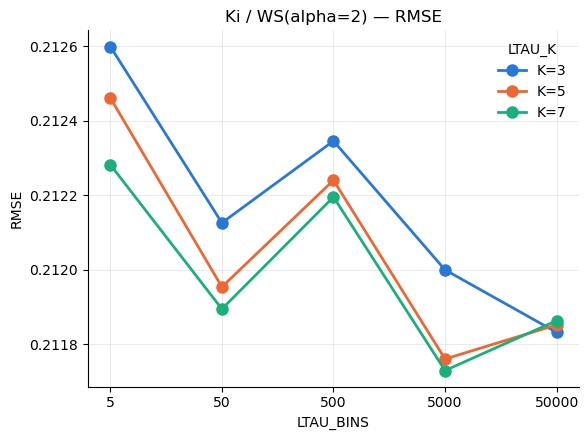

[saved] /data/rlawlsgurjh/work/gitlab/CUE/cmfe/results/plots/ltau_param_lineplot/Ki/WS(alpha=2)_rmse.png


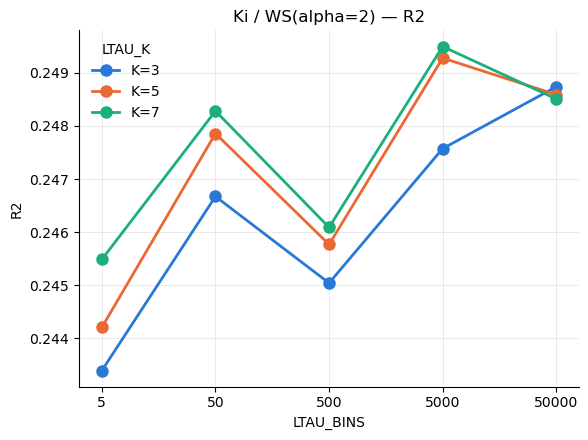

[saved] /data/rlawlsgurjh/work/gitlab/CUE/cmfe/results/plots/ltau_param_lineplot/Ki/WS(alpha=2)_r2.png


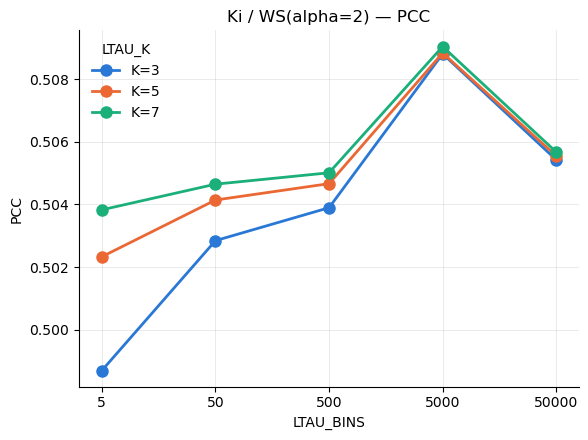

[saved] /data/rlawlsgurjh/work/gitlab/CUE/cmfe/results/plots/ltau_param_lineplot/Ki/WS(alpha=2)_pcc.png


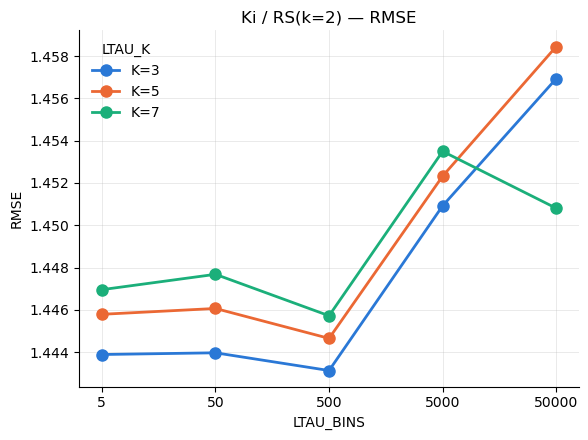

[saved] /data/rlawlsgurjh/work/gitlab/CUE/cmfe/results/plots/ltau_param_lineplot/Ki/RS(k=2)_rmse.png


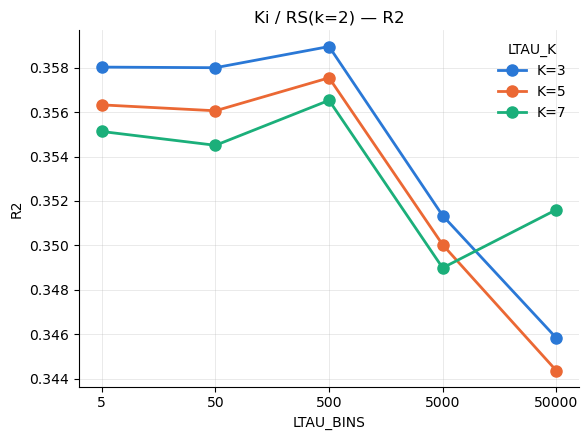

[saved] /data/rlawlsgurjh/work/gitlab/CUE/cmfe/results/plots/ltau_param_lineplot/Ki/RS(k=2)_r2.png


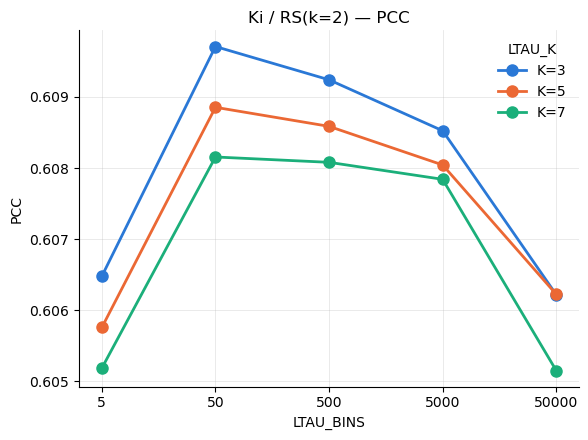

[saved] /data/rlawlsgurjh/work/gitlab/CUE/cmfe/results/plots/ltau_param_lineplot/Ki/RS(k=2)_pcc.png


In [4]:
for dataset in DATASETS:
    for target in TARGETS:
        for metric in METRICS:
            plot_lineplot(df_all, dataset, target, metric)